# EDA: SoccerNet features + labels

Scope: SoccerNet play-recognition data only (ResNET_TF2_PCA512 features + Labels-v2).
No StatsBomb/formation EDA and no modelling here.

**"All games" = every game on disk.** `scripts/download_soccernet.py` fetches the
`valid` split only, so counts below describe that split, not all of SoccerNet.
Loaders: `src/data_loaders.py`. Figures are saved to `reports/figures/`.

In [1]:
import sys
from pathlib import Path

# Make the repo root the working dir so relative paths (data/raw/...) resolve.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import os
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data_loaders as dl

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Chart style: one hue for single-series magnitude, recessive grid, neutral text.
BAR = "#2a6fb0"
INK, MUTED, GRID = "#1f2328", "#59636e", "#d8dee4"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "text.color": INK, "axes.labelcolor": MUTED, "axes.edgecolor": GRID,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def save(fig, name):
    p = FIG_DIR / name
    fig.savefig(p, bbox_inches="tight", facecolor="white")
    print("saved", p.relative_to(ROOT))

## 1. Game inventory

In [2]:
games = list(dl.iter_games())
inv = pd.DataFrame([{"league": g.league, "season": g.season, "game": g.game} for g in games])
print(f"{len(inv)} games | {inv.league.nunique()} leagues | {inv.groupby(['league','season']).ngroups} league-seasons")
by_ls = inv.groupby(["league", "season"]).size().rename("games").reset_index()
by_ls

100 games | 6 leagues | 17 league-seasons


,league,season,games
0,england_epl,2014-2015,1
1,england_epl,2015-2016,12
2,england_epl,2016-2017,6
3,europe_uefa-champions-league,2014-2015,8
4,europe_uefa-champions-league,2015-2016,10
5,europe_uefa-champions-league,2016-2017,2
6,france_ligue-1,2015-2016,1
7,france_ligue-1,2016-2017,8
8,germany_bundesliga,2014-2015,2
9,germany_bundesliga,2015-2016,4


saved reports\figures\01_games_per_league.png


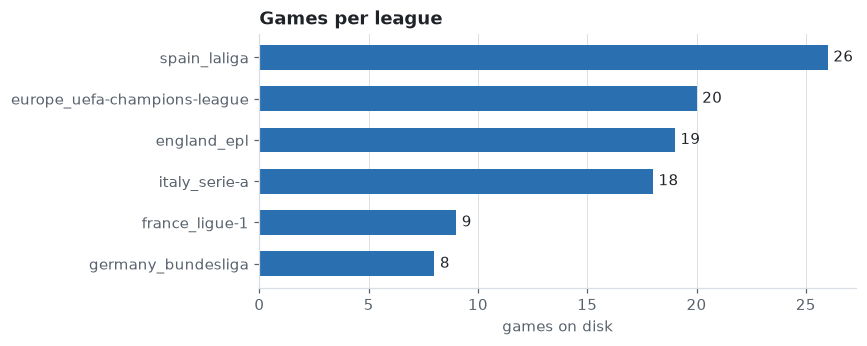

In [3]:
by_league = inv.groupby("league").size().sort_values().rename("games")
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(by_league.index, by_league.values, color=BAR, height=0.6)
for y, v in enumerate(by_league.values):
    ax.text(v + by_league.max() * 0.01, y, str(v), va="center", color=INK)
ax.set_xlabel("games on disk"); ax.set_title("Games per league")
ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
save(fig, "01_games_per_league.png"); plt.show()

## 2. Feature arrays: shapes and value distributions

In [4]:
fs = dl.build_feature_summary()
present = fs[fs.file_present]
print(f"{len(fs)} (game, half) slots; {len(present)} arrays present")
print("feature_dim values:", present.feature_dim.unique().tolist(), "| dtypes:", present.dtype.unique().tolist())
print(f"total frames: {int(present.n_frames.sum()):,}")
present.groupby("half")["n_frames"].describe().round(1)

200 (game, half) slots; 200 arrays present
feature_dim values: [512] | dtypes: ['float32']
total frames: 1,097,997


,count,mean,std,min,25%,50%,75%,max
half,,,,,,,,
1,100.0,5435.4,97.0,5399.0,5400.0,5400.0,5400.0,5922.0
2,100.0,5544.6,193.5,5399.0,5400.0,5400.0,5739.2,6118.0


In [5]:
present[["n_frames", "min", "max", "mean", "std", "n_nan", "n_inf"]].describe().round(3)

,n_frames,min,max,mean,std,n_nan,n_inf
count,200.000,200.000,200.000,200.000,200.000,200.0,200.0
mean,5489.985,-33.230,29.191,0.001,1.355,0.0,0.0
std,162.205,0.720,2.797,0.018,0.050,0.0,0.0
min,5399.000,-36.033,22.748,-0.044,1.223,0.0,0.0
25%,5400.000,-33.714,27.146,-0.012,1.321,0.0,0.0
50%,5400.000,-33.175,29.209,-0.001,1.352,0.0,0.0
75%,5507.250,-32.717,31.068,0.013,1.394,0.0,0.0
max,6118.000,-31.105,39.077,0.052,1.490,0.0,0.0


saved reports\figures\02_feature_summaries.png


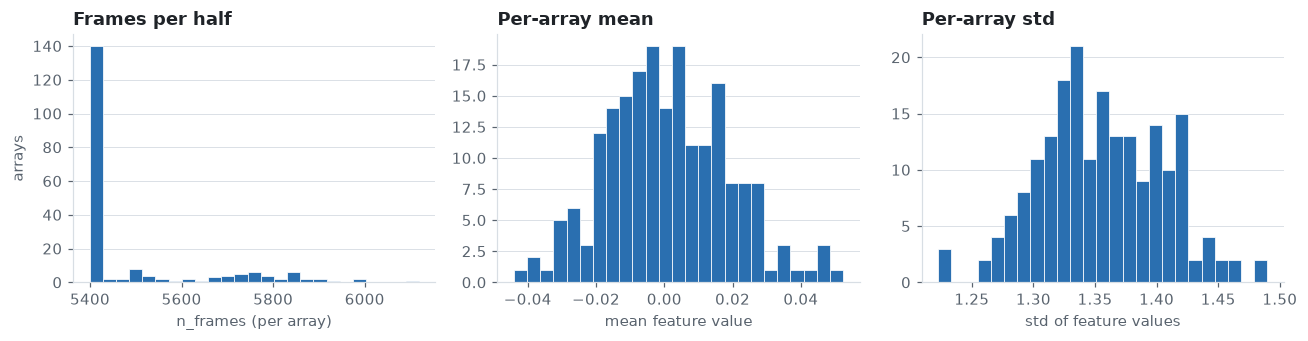

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].hist(present.n_frames, bins=25, color=BAR, edgecolor="white", lw=0.5)
axes[0].set_title("Frames per half"); axes[0].set_xlabel("n_frames (per array)"); axes[0].set_ylabel("arrays")
axes[1].hist(present["mean"], bins=25, color=BAR, edgecolor="white", lw=0.5)
axes[1].set_title("Per-array mean"); axes[1].set_xlabel("mean feature value")
axes[2].hist(present["std"], bins=25, color=BAR, edgecolor="white", lw=0.5)
axes[2].set_title("Per-array std"); axes[2].set_xlabel("std of feature values")
for a in axes: a.grid(axis="y", color=GRID, lw=0.6); a.set_axisbelow(True)
fig.tight_layout(); save(fig, "02_feature_summaries.png"); plt.show()

sampled frames: (10000, 512)


saved reports\figures\03_feature_value_distribution.png


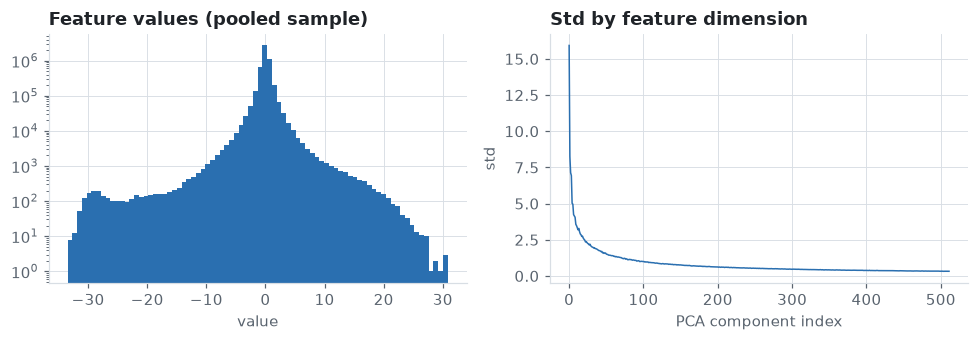

In [7]:
# Pooled value distribution from a random sample of frames (avoid loading everything into one array).
rng = np.random.default_rng(0)
sample = []
for g in games:
    for h, f in enumerate(dl.load_game(g, mmap=True)["features"], start=1):
        if f is not None and len(f):
            idx = np.sort(rng.choice(len(f), size=min(50, len(f)), replace=False))
            sample.append(np.asarray(f[idx]))
sample = np.concatenate(sample)
print("sampled frames:", sample.shape)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].hist(sample.ravel(), bins=80, color=BAR, edgecolor="none")
axes[0].set_title("Feature values (pooled sample)"); axes[0].set_xlabel("value"); axes[0].set_yscale("log")
axes[1].plot(sample.std(axis=0), color=BAR, lw=1)
axes[1].set_title("Std by feature dimension"); axes[1].set_xlabel("PCA component index"); axes[1].set_ylabel("std")
for a in axes: a.grid(color=GRID, lw=0.6); a.set_axisbelow(True)
fig.tight_layout(); save(fig, "03_feature_value_distribution.png"); plt.show()

## 3. Annotations: per-class counts across all games (class imbalance)

In [8]:
ann = dl.build_annotation_table()
tbl = dl.class_count_table(ann)
print(f"{len(ann):,} annotations | {ann.game_id.nunique()} games | {ann.label.nunique()} distinct labels (expected 17)")
tbl.assign(share=(tbl.share * 100).round(2)).rename(columns={"share": "share_%"})

21,447 annotations | 100 games | 17 distinct labels (expected 17)


,count,n_games,share_%
label,,,
Ball out of play,6253,100,29.16
Throw-in,3718,100,17.34
Foul,2176,100,10.15
Indirect free-kick,1907,99,8.89
Clearance,1516,100,7.07
Shots on target,1182,100,5.51
Shots off target,984,100,4.59
Corner,953,100,4.44
Substitution,560,100,2.61


In [9]:
nonzero = tbl[tbl["count"] > 0]
imb = nonzero["count"].max() / nonzero["count"].min()
print(f"Most common: {nonzero.index[0]} ({nonzero['count'].iloc[0]:,}); rarest: {nonzero.index[-1]} ({nonzero['count'].iloc[-1]:,})")
print(f"Imbalance ratio (max/min): {imb:,.0f}x")
print(f"Top 3 classes hold {tbl.share.head(3).sum():.1%} of annotations; bottom 3 hold {tbl.share.tail(3).sum():.2%}")

Most common: Ball out of play (6,253); rarest: Yellow->red card (8)
Imbalance ratio (max/min): 782x
Top 3 classes hold 56.6% of annotations; bottom 3 hold 0.27%


saved reports\figures\04_class_balance.png


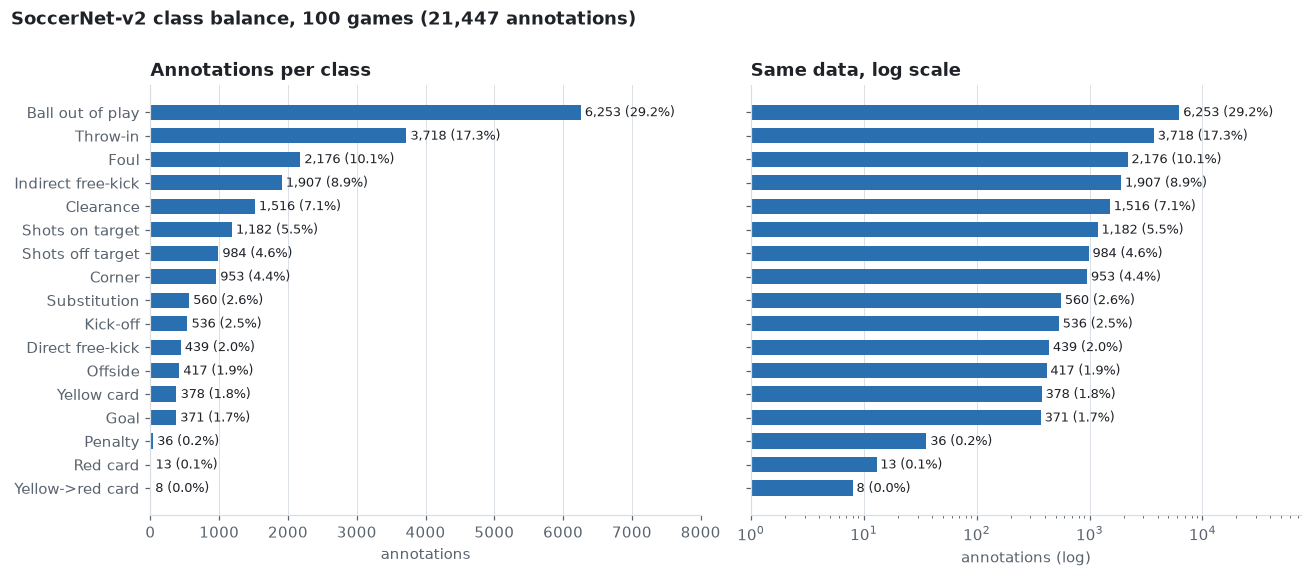

In [10]:
t = tbl.iloc[::-1]  # ascending so the largest bar is on top of a horizontal chart
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
for ax, log in zip(axes, (False, True)):
    ax.barh(t.index, t["count"], color=BAR, height=0.65)
    for y, (c, s) in enumerate(zip(t["count"], t["share"])):
        ax.text(c * (1.08 if log else 1) + (0 if log else t["count"].max() * 0.01), y,
                f"{c:,} ({s:.1%})", va="center", fontsize=8.5, color=INK)
    ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
    if log:
        ax.set_xscale("log"); ax.set_xlim(1, t["count"].max() * 12)
        ax.set_title("Same data, log scale"); ax.set_xlabel("annotations (log)")
    else:
        ax.set_xlim(0, t["count"].max() * 1.28)
        ax.set_title("Annotations per class"); ax.set_xlabel("annotations")
fig.suptitle(f"SoccerNet-v2 class balance, {ann.game_id.nunique()} games ({len(ann):,} annotations)",
             x=0.01, ha="left", fontweight="bold", y=1.0)
fig.tight_layout(); save(fig, "04_class_balance.png"); plt.show()

saved reports\figures\05_class_coverage.png


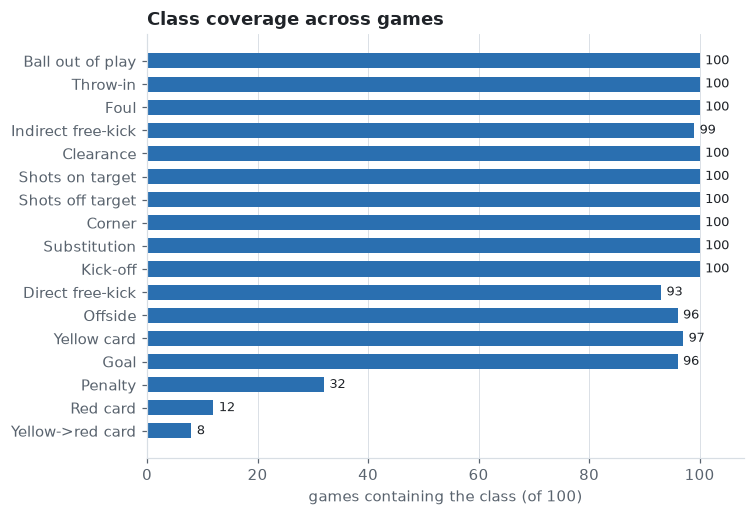

In [11]:
# Number of games each class appears in (rare classes may be concentrated in few games).
g = tbl["n_games"].iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(g.index, g.values, color=BAR, height=0.65)
for y, v in enumerate(g.values):
    ax.text(v + 1, y, str(v), va="center", fontsize=8.5)
ax.set_xlim(0, ann.game_id.nunique() * 1.08)
ax.set_xlabel(f"games containing the class (of {ann.game_id.nunique()})"); ax.set_title("Class coverage across games")
ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
save(fig, "05_class_coverage.png"); plt.show()

## 4. Data-quality checks

In [12]:
checks = {}

# Files present
checks["games with a missing feature file"] = int((~fs.file_present).groupby(fs.game_id).any().sum())
checks["games missing Labels-v2.json"] = sum(not (g.path / dl.LABELS_FILE).exists() for g in games)

# Empty / malformed arrays
checks["empty arrays (0 frames)"] = int((present.n_frames == 0).sum())
checks["arrays with unexpected feature_dim != 512"] = int((present.feature_dim != 512).sum())
checks["arrays containing NaN"] = int((present.n_nan > 0).sum())
checks["arrays containing Inf"] = int((present.n_inf > 0).sum())
checks["arrays with zero variance"] = int((present["std"] == 0).sum())

# Labels
n_ann_per_game = ann.groupby("game_id").size()
checks["games with zero annotations"] = len(games) - n_ann_per_game.size
checks["annotations with unknown class"] = int((~ann.label.isin(dl.CLASSES_V2)).sum())
checks["annotations with null label/time/position"] = int(
    ann[["label", "half", "seconds", "position_ms"]].isna().any(axis=1).sum())
checks["annotations with half not in {1,2}"] = int((~ann.half.isin([1, 2])).sum())
checks["exact duplicate annotations"] = int(ann.duplicated(["game_id", "label", "half", "position_ms", "team"]).sum())
checks["visibility values"] = ann.visibility.value_counts().to_dict()

# Label time vs feature length (features are ~2 frames/sec: n_frames / 2 = seconds covered)
rate = 2.0
half_len = present.set_index(["game_id", "half"])["n_frames"] / rate
last = ann.groupby(["game_id", "half"])["seconds"].max()
j = pd.concat([last.rename("last_label_s"), half_len.rename("feature_s")], axis=1).dropna()
over = j[j.last_label_s > j.feature_s + 1]
checks["(game,half) where last label is after end of features (+1s)"] = len(over)

pd.Series(checks, name="result").to_frame()

,result
games with a missing feature file,0
games missing Labels-v2.json,0
empty arrays (0 frames),0
arrays with unexpected feature_dim != 512,0
arrays containing NaN,0
arrays containing Inf,0
arrays with zero variance,0
games with zero annotations,0
annotations with unknown class,0
annotations with null label/time/position,0


In [13]:
# Frames-per-second sanity: seconds covered per half should be ~45-60+ minutes
(present.assign(minutes=present.n_frames / rate / 60)
        .groupby("half")["minutes"].describe().round(1))

,count,mean,std,min,25%,50%,75%,max
half,,,,,,,,
1,100.0,45.3,0.8,45.0,45.0,45.0,45.0,49.4
2,100.0,46.2,1.6,45.0,45.0,45.0,47.8,51.0


In [14]:
over.head(10) if len(over) else "No label timestamps exceed the feature length." 

'No label timestamps exceed the feature length.'

## 5. Summary

In [15]:
print(f"Games: {len(games)} ({inv.league.nunique()} leagues) | arrays: {len(present)} | frames: {int(present.n_frames.sum()):,} x {int(present.feature_dim.iloc[0])}d")
print(f"Annotations: {len(ann):,} across {ann.label.nunique()} classes | imbalance max/min = {imb:,.0f}x")
print("Top 5:", ", ".join(f"{k} {v:.1%}" for k, v in tbl.share.head(5).items()))
print("Bottom 3:", ", ".join(f"{k} ({int(tbl.loc[k,'count'])})" for k in tbl.index[-3:]))
issues = {k: v for k, v in checks.items() if isinstance(v, int) and v > 0}
print("Data-quality flags:", issues if issues else "none")

Games: 100 (6 leagues) | arrays: 200 | frames: 1,097,997 x 512d
Annotations: 21,447 across 17 classes | imbalance max/min = 782x
Top 5: Ball out of play 29.2%, Throw-in 17.3%, Foul 10.1%, Indirect free-kick 8.9%, Clearance 7.1%
Bottom 3: Penalty (36), Red card (13), Yellow->red card (8)
Data-quality flags: {'exact duplicate annotations': 7}
